# $\text{Sanity checks}$

In [2]:
import pandas as pd
import numpy as np
from scipy import interpolate
from scipy import integrate

from Atenuation import Atenuation_csv
from scipy.interpolate import interp1d
from scipy.integrate import simpson
import matplotlib.pyplot as plt
plt.style.use("/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Scripts/lz_style.mplstyle")
import os
cwd = os.getcwd()

In [20]:
MD_control = pd.read_csv('Data/MD_cos_1.csv',sep=';')
MD_control_0 = pd.read_csv('Data/MD_cos_0.csv',sep=';')
PB_control = pd.read_csv('Data/PB_cos_1.csv',sep=';')
PB_control_0 = pd.read_csv('Data/PB_cos_0.csv',sep=';')

E_control_MD_1 = MD_control['E[GeV]'].values
F_control_MD_1 = MD_control['flux[GeV-1s-1cm-2sr-1]'].values

E_control_PB_1 = PB_control['E[GeV]'].values
F_control_PB_1 = PB_control['flux[GeV-1s-1cm-2sr-1]'].values

E_control_MD_0 = MD_control_0['E[GeV]'].values
F_control_MD_0 = MD_control_0['flux[GeV-1s-1cm-2sr-1]'].values

E_control_PB_0 = PB_control_0['E[GeV]'].values
F_control_PB_0 = PB_control_0['flux[GeV-1s-1cm-2sr-1]'].values

In [21]:
df_pi0_ = pd.read_csv( 'Data/MCP_FROM_PI0_SURFACE.csv')
df_eta_ = pd.read_csv('Data/mCP_mesons/MCP_FROM_ETA_SURFACE.csv')
df_omega_ = pd.read_csv('Data/mCP_mesons/MCP_FROM_OMEGA_SURFACE.csv')
df_rho_ = pd.read_csv('Data/mCP_mesons/MCP_FROM_RHO_SURFACE.csv')
df_phi_ = pd.read_csv('Data/mCP_mesons/MCP_FROM_PHI_SURFACE.csv')
df_jpsi_ = pd.read_csv('Data/mCP_mesons/MCP_FROM_JPSI_SURFACE.csv')
df_PB = pd.read_csv('Data/mCP_PB_differential_flux_surface.csv')

eps2 = 1e-4
cos_theta = [0,1]
m_mcp = 0.1

In [22]:
m_mcp_PB = df_PB['m(GeV)'].unique()[35]

In [23]:
E_chi_0 = []
E_chi_1 = []
f_diff_0 = []
f_diff_1 = []

for ct in cos_theta:
    df_eta = df_eta_[(df_eta_['eps2'] == eps2) & (df_eta_['cosTh'] == ct) & (df_eta_['m(GeV)'] == m_mcp)]
    df_omega = df_omega_[(df_omega_['eps2'] == eps2) & (df_omega_['cosTh'] == ct) & (df_omega_['m(GeV)'] == m_mcp)]
    df_rho = df_rho_[(df_rho_['eps2'] == eps2) & (df_rho_['cosTh'] == ct) & (df_rho_['m(GeV)'] == m_mcp)]
    df_phi = df_phi_[(df_phi_['eps2'] == eps2) & (df_phi_['cosTh'] == ct) & (df_phi_['m(GeV)'] == m_mcp)]
    df_jpsi = df_jpsi_[(df_jpsi_['eps2'] == eps2) & (df_jpsi_['cosTh'] == ct) & (df_jpsi_['m(GeV)'] == m_mcp)]
    df_PB_ = df_PB[(df_PB['eps2'] == eps2) & (df_PB['cos_theta'] == ct) & (df_PB['m(GeV)'] == m_mcp_PB)]
    #df_total = df_total_[(df_total_['eps2'] == eps2) & (df_total_['cos'] == ct) & (df_total_['m(GeV)'] == m_mcp)]
    E = [
        df_eta['Energy (GeV)'].values,
        df_omega['Energy (GeV)'].values,
        df_rho['Energy (GeV)'].values,
        df_phi['Energy (GeV)'].values,
        df_jpsi['Energy (GeV)'].values,
        df_PB_['Energy(GeV)'].values,
        #df_total['Energy (GeV)'].values,
    ]
    F = [
        df_eta['dphi_dEdCth(1/GeV/s/cm2)'].values/(2*np.pi),
        df_omega['dphi_dEdCth(1/GeV/s/cm2)'].values/(2*np.pi),
        df_rho['dphi_dEdCth(1/GeV/s/cm2)'].values/(2*np.pi),
        df_phi['dphi_dEdCth(1/GeV/s/cm2)'].values/(2*np.pi),
        df_jpsi['dphi_dEdCth(1/GeV/s/cm2)'].values/(2*np.pi),
        df_PB_['dphi_dEdCth(1/GeV/s/cm2/sr)'].values,
        #df_total['flux_total'].values,
    ]

    if ct == 0:
        E_chi_0 = E
        f_diff_0 = F
    elif ct == 1:
        E_chi_1 = E
        f_diff_1 = F

E_chi = [E_chi_0, E_chi_1]
f_diff = [f_diff_0, f_diff_1]

In [24]:
E_chi_0[-1]

array([ 0.1       ,  0.11234493,  0.12621384,  0.14179486,  0.15929934,
        0.17896474,  0.20105782,  0.22587828,  0.2537628 ,  0.28508965,
        0.32028378,  0.35982261,  0.40424247,  0.45414594,  0.51020996,
        0.57319504,  0.64395559,  0.72345149,  0.8127611 ,  0.91309593,
        1.02581702,  1.15245346,  1.29472308,  1.45455579,  1.63411975,
        1.83585077,  2.06248534,  2.3170978 ,  2.603142  ,  2.92449818,
        3.28552556,  3.69112153,  4.14678806,  4.65870633,  5.23382057,
        5.87993229,  6.60580607,  7.4212885 ,  8.33744169,  9.3666934 ,
       10.52300556, 11.82206369, 13.2814897 , 14.92108089, 16.76307854,
       18.83246959, 21.1573256 , 23.76918357, 26.70347369, 30.        ])

In [25]:
def interpolate_total_flux(E_list, F_list, n_points=100):
    common_mass_ = np.unique(np.concatenate([np.asarray(m) for m in E_list]))
    

    common_mass = np.logspace(
        np.log10(common_mass_[0]),
        np.log10(common_mass_[-1]),
        n_points
    )

    flujo_md_interp = []
    for j in range(len(E_list)):
        mass_sorted_idx = np.argsort(E_list[j])
        mass_sorted = np.asarray(E_list[j])[mass_sorted_idx]
        flux_sorted = np.asarray(F_list[j])[mass_sorted_idx]

        unique_mask = np.concatenate(([True], np.diff(mass_sorted) != 0))
        mass_unique = mass_sorted[unique_mask]
        flux_unique = flux_sorted[unique_mask]

        flujo_md_interp.append(
            np.interp(common_mass, mass_unique, flux_unique, left=0.0, right=0.0)
        )

    flujo_total = np.sum(flujo_md_interp, axis=0)
    return common_mass, np.array(flujo_total)

common_e_0, flujo_total_0 = interpolate_total_flux(E_chi_0[:-1], f_diff_0[:-1])
common_e_1, flujo_total_1 = interpolate_total_flux(E_chi_1[:-1], f_diff_1[:-1])

In [26]:
def D_overburden(d,theta):
    '''
    Calculates the overburden distance D for a given depth d and zenith angle theta.
    d: depth in meters (of the experiment)
    theta: zenith angle in radians
    '''
    R_t = 6.378e6 # [m] Radio de la tierra
    D = np.sqrt((R_t-d)**2*((np.cos(theta))**2)+d*(2*R_t-d))-(R_t-d)*np.cos(theta)
    return D # resultado en METROS

# Función R
def R_average(eps, Ei, Ef, a=None, b=None):
    '''
    Calculates the average distance R that a mCP travels in the earth 
        eps: mCP charge fraction (e.g., 1e-3 for a mCP with charge 0.001e)
        Ei: initial energy of the mCP in the surface(in GeV)
        Ef: final energy of the mCP in the surface(in GeV)
        returns: R in meters using the formula R = (1/eps^2)*(1/b)*log((1+(a/b)*Ei)/(1+(a/b)*Ef))*(1/2.65)

    b is in 1/mwe units, so we may need to convert it to 1/m since D is 
    in meters. The paper says that this value was calculated for a "standard
    rock shielding so we consider 1 mwe = (1/2.65) m of rock "
    '''

    if a is None:
        a = 0.223 # [GeV/mwe]
    if b is None:
        b = 4.64e-4 # [1/mwe]

    R = ((1/(eps**2))*(1/b))*np.log((1+(b/a)*Ei)/(1+(b/a)*Ef)) # [mwe]
    R = R # [m]
    return R 

def P_arrival(eps, Ei, Ef, d, theta):
    '''
    Calculates the probability of arrival of a mCP at the detector given its charge fraction, initial and final energy, depth of the experiment, and zenith angle.
    eps: mCP charge fraction
    Ei: initial energy of the mCP in GeV
    Ef: final energy of the mCP in GeV
    d: depth of the experiment in meters
    theta: zenith angle in radians
    returns: probability of arrival at the detector
    '''
    D = D_overburden(d, theta)*2.65 # Calculate overburden distance D
    R = R_average(eps, Ei, Ef) # Calculate average distance R that the mCP travels in the earth
    P = np.exp(-D/R) # Probability of arrival using the formula P = exp(-D/R)
    return P

In [27]:
idx = np.argsort(E_control_PB_1)

E_CONTROL_PB_1 = E_control_PB_1[idx]
F_CONTROL_PB_1 = F_control_PB_1[idx]

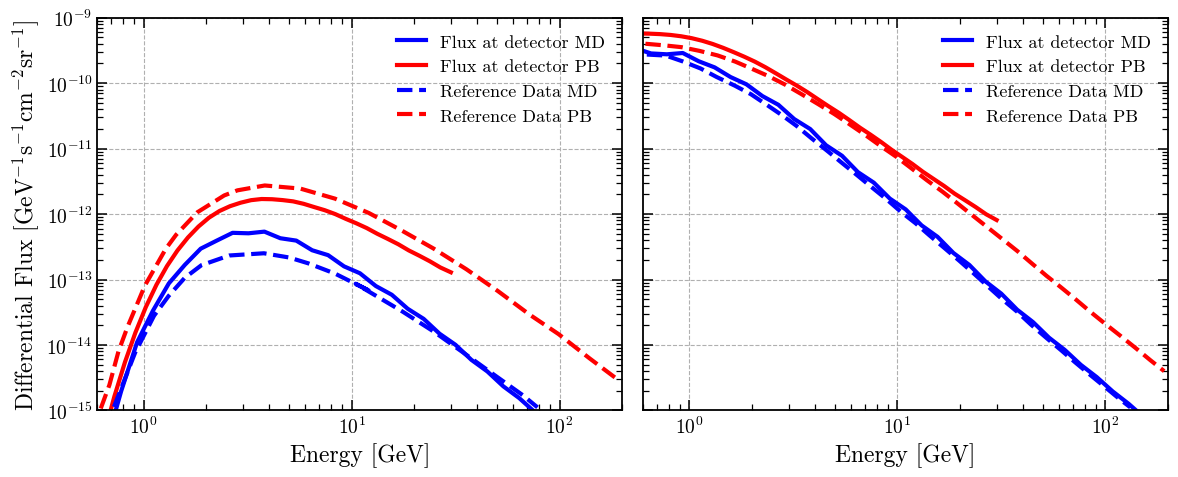

In [28]:
fig, ax = plt.subplots(1,2,figsize=(12, 5),sharey=True)

p_arrival_0 = P_arrival((1e-4)**(1/2), common_e_0,0,1500, np.pi/2) 
p_arrival_1 = P_arrival((1e-4)**(1/2), common_e_1,0,1500, 0) 
p_arrival_0_PB = P_arrival((1e-4)**(1/2), E_chi_0[-1],0,1500, np.pi/2) 
p_arrival_1_PB = P_arrival((1e-4)**(1/2), E_chi_1[-1],0,1500, 0) 

ax[0].plot(common_e_0, flujo_total_0*p_arrival_0, label=r'Flux at detector MD', color='blue', linewidth=3,linestyle='-' )
#ax[0].plot(common_e_0, flujo_total_0, label=r'Surface flux MD', color='blue', linewidth=3)
#ax[0].plot(E_chi_0[-1], f_diff_0[-1], label=r'Surface flux PB', color='red', linewidth=3 )
ax[0].plot(E_chi_0[-1], ((f_diff_0[-1]*p_arrival_0_PB)), label=r'Flux at detector PB ', color='red', linewidth=3,linestyle='-' )



#ax[1].plot(common_e_1, flujo_total_1, label=r'Surface flux MD', color='blue', linewidth=3)
ax[1].plot(common_e_1, flujo_total_1*p_arrival_1, label=r'Flux at detector MD', color='blue', linewidth=3)
#ax[1].plot(E_chi_1[-1], f_diff_1[-1], label=r'Surface flux PB', color='red', linewidth=3 )
ax[1].plot(E_chi_1[-1], f_diff_1[-1]*p_arrival_1_PB, label=r'Flux at detector PB ', color='red', linewidth=3)


ax[1].plot(E_control_MD_1,F_control_MD_1,label=r'Reference Data MD', color='blue', linewidth=3,linestyle='--')
ax[0].plot(E_control_MD_0,F_control_MD_0,label=r'Reference Data MD', color='blue', linewidth=3,linestyle='--')
ax[0].plot(E_control_PB_0,F_control_PB_0,label=r'Reference Data PB', color='red', linewidth=3,linestyle='--')
ax[1].plot(E_CONTROL_PB_1,F_CONTROL_PB_1,label=r'Reference Data PB', color='red', linewidth=3,linestyle='--')


ax[0].set_xlabel('Energy [GeV]', fontsize=17)
ax[0].set_ylabel(r'Differential Flux [$\text{GeV}^{-1}\text{s}^{-1}\text{cm}^{-2}\text{sr}^{-1}$]', fontsize=17)
ax[1].set_xlabel('Energy [GeV]', fontsize=17)

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
ax[1].set_yscale('log')

ax[0].set_xlim([6e-1, 2e2])
ax[1].set_xlim([6e-1, 2e2])
ax[0].set_ylim([1e-15, 1e-9])
ax[1].set_ylim([1e-15, 1e-9])


ax[0].grid(True, ls="--")
ax[1].grid(True,  ls="--")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.savefig('/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Reporte/Figures/differential_flux_sanity_check.pdf', dpi=300)
plt.show()


In [29]:
E = np.logspace(np.log10(np.min(E_control_MD_0)), np.log10(np.max(E_control_MD_0)), 50)
flux_1 = np.interp(E,common_e_0, flujo_total_0)
flujo_LZ = np.interp(E,E_control_MD_0,F_control_MD_0)
print(E[0], E[-1])



0.720187 78.27650000000001


In [30]:
cociente_ = (flujo_LZ/flux_1)
cociente = cociente_[cociente_ <1]
p_arrival_05 = P_arrival((1e-4)**(1/2), E,0.3,1500, np.pi/2) 
p_arrival_0 = P_arrival((1e-4)**(1/2), E,0,1500, np.pi/2)
p_arrival_07 = P_arrival((1e-4)**(1/2), E,0.7,1500, np.pi/2)


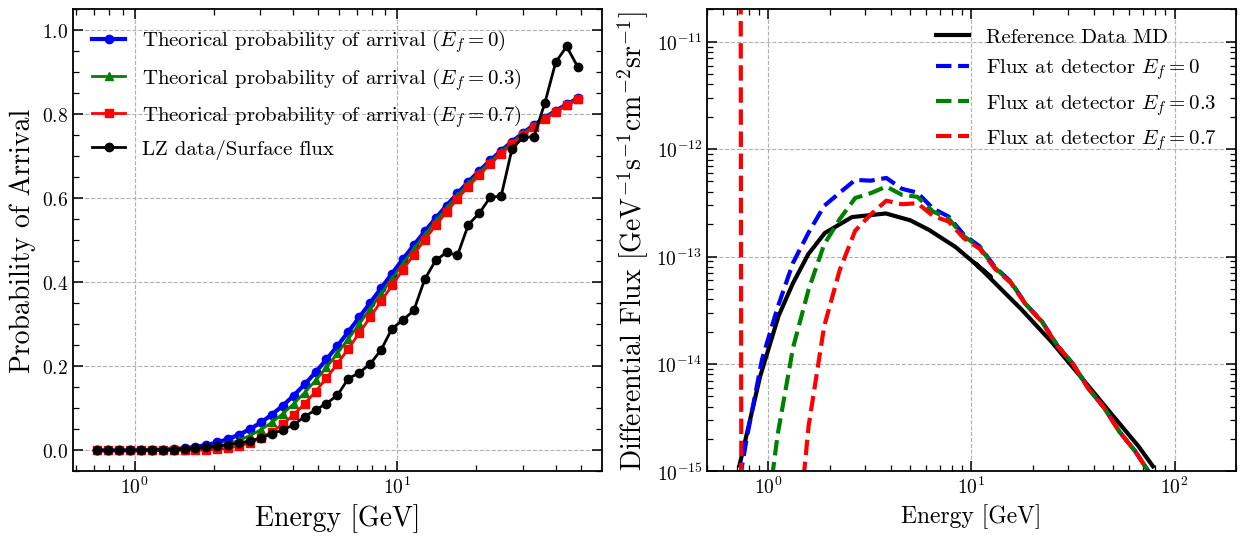

In [31]:
fig,axes = plt.subplots(1,2,figsize=(15, 6))
p_arr_0 = P_arrival((1e-4)**(1/2), common_e_0,0,1500, np.pi/2)
p_arr_03 = P_arrival((1e-4)**(1/2), common_e_0,0.3,1500, np.pi/2)
p_arr_07 = P_arrival((1e-4)**(1/2), common_e_0,0.7,1500, np.pi/2) 

axes[0].plot(E[cociente_<1], p_arrival_0[cociente_<1], label=r'Theorical probability of arrival ($E_f = 0$)', color = 'blue',marker = 'o',  linewidth=3)
axes[0].plot(E[cociente_<1], p_arrival_05[cociente_<1], label=r'Theorical probability of arrival ($E_f = 0.3$)',color = 'green',marker = '^', linewidth=2)
axes[0].plot(E[cociente_<1], p_arrival_07[cociente_<1], label=r'Theorical probability of arrival ($E_f = 0.7$)', color = 'red',marker = 's', linewidth=2)
axes[0].plot(E[cociente_<1],cociente,label='LZ data/Surface flux', color='k', marker = 'o', linewidth=2)
axes[0].set_xlabel('Energy [GeV]',fontsize=20)
axes[0].set_ylabel('Probability of Arrival',fontsize=20)
axes[0].set_xscale('log')
axes[0].set_ylim([-0.05, 1.05])
axes[0].grid(linestyle='--')
axes[0].legend(fontsize=15)

axes[1].plot(E_control_MD_0,F_control_MD_0,label=r'Reference Data MD', color='k', linewidth=3)

axes[1].plot(common_e_0, flujo_total_0*p_arr_0, label=r'Flux at detector $E_f = 0$', color='blue', linewidth=3,linestyle='--' )
axes[1].plot(common_e_0, flujo_total_0*p_arr_03, label=r'Flux at detector $E_f = 0.3$', color='green', linewidth=3,linestyle='--' )
axes[1].plot(common_e_0, flujo_total_0*p_arr_07, label=r'Flux at detector $E_f = 0.7$', color='red', linewidth=3,linestyle='--' )
axes[1].set_xlabel('Energy [GeV]', fontsize=17)
axes[1].set_ylabel(r'Differential Flux [$\text{GeV}^{-1}\text{s}^{-1}\text{cm}^{-2}\text{sr}^{-1}$]', fontsize=20)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlim([5e-1, 2e2])
axes[1].set_ylim([1e-15, 2e-11])
axes[1].grid(linestyle='--')
axes[1].legend(fontsize=15)





plt.savefig('/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Reporte/Figures/probability_of_arrival_check.pdf', dpi=300)


In [32]:
Ef = np.logspace(-9, np.log10(np.min(common_e_0)), 50)
p_arr_cos0 = P_arrival((1e-4)**(1/2), np.min(common_e_0),Ef[:-2],1500, np.pi/2)
p_arr_cos1 = P_arrival((1e-4)**(1/2), np.min(common_e_0),Ef[:-2],1500, 0)

p_arr_cos0_eps2 = P_arrival((1e-6)**(1/2), np.min(common_e_0),Ef[:-2],1500, np.pi/2)
p_arr_cos1_eps2 = P_arrival((1e-6)**(1/2), np.min(common_e_0),Ef[:-2],1500, 0)

p_arr_cos0_eps3 = P_arrival((1e-8)**(1/2), np.min(common_e_0),Ef[:-2],1500, np.pi/2)
p_arr_cos1_eps3 = P_arrival((1e-8)**(1/2), np.min(common_e_0),Ef[:-2],1500, 0)

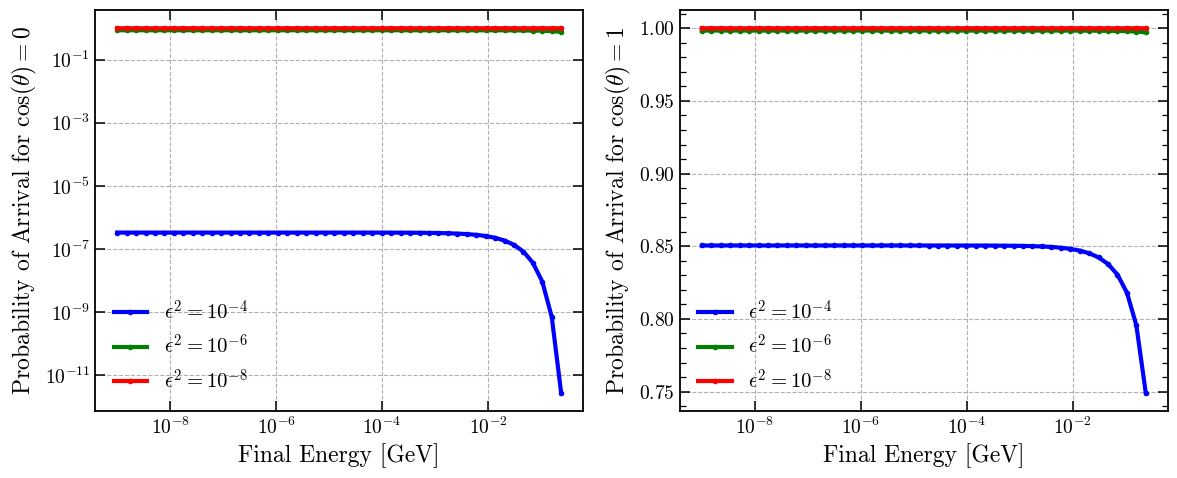

In [33]:
fig,axes = plt.subplots(1,2,figsize=(12, 5))
axes[0].plot(Ef[:-2], p_arr_cos0, label=r'$\epsilon^2 = 10^{-4}$', color = 'blue',marker = '.',  linewidth=3)
axes[0].plot(Ef[:-2], p_arr_cos0_eps2, label=r'$\epsilon^2 = 10^{-6}$', color = 'green',marker = '.',  linewidth=3)
axes[0].plot(Ef[:-2], p_arr_cos0_eps3, label=r'$\epsilon^2 = 10^{-8}$', color = 'red',marker = '.',  linewidth=3)
axes[0].set_xlabel('Final Energy [GeV]', fontsize=17)
axes[0].set_ylabel(r'Probability of Arrival for $\cos(\theta) = 0$', fontsize=17)
axes[0].set_xscale('log')

axes[0].grid(linestyle='--')
axes[0].legend(fontsize=15)
axes[0].set_yscale('log')

axes[1].plot(Ef[:-2], p_arr_cos1, label=r'$\epsilon^2 = 10^{-4}$', color = 'blue',marker = '.',  linewidth=3)
axes[1].plot(Ef[:-2], p_arr_cos1_eps2, label=r'$\epsilon^2 = 10^{-6}$', color = 'green',marker = '.',  linewidth=3)
axes[1].plot(Ef[:-2], p_arr_cos1_eps3, label=r'$\epsilon^2 = 10^{-8}$', color = 'red',marker = '.',  linewidth=3)

axes[1].set_xlabel('Final Energy [GeV]', fontsize=17)
axes[1].set_ylabel(r'Probability of Arrival for $\cos(\theta) = 1$', fontsize=17)
axes[1].set_xscale('log')

axes[1].grid(linestyle='--')
axes[1].legend(fontsize=15)
plt.tight_layout()
plt.savefig('/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Reporte/Figures/probability_of_arrival_final_energy.pdf', dpi=300)

# $\text{Zenith angle dependence}$

In [34]:
mesones = ['PI0', 'ETA', 'RHO', 'OMEGA', 'PHI', 'JPSI']
path = '/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Scripts/Data/'
for meson in mesones:
    # 1) Leo el archivo y le pongo nombres cortos a las columnas
    df = pd.read_csv(path + 'MCP_FROM_' + meson + '_SURFACE.csv')
    df.columns = ['flujo', 'E', 'cos', 'm', 'eps2']

    # 2) Separo el flujo vertical (cos θ = 1)
    vertical = df[df['cos'] == 1.0][['E', 'm', 'eps2', 'flujo']]
    vertical = vertical.rename(columns={'flujo': 'flujo_vertical'})

    print('\n=====', meson, '=====')

    # 3) Para cada cos θ distinto de 1, divido por el flujo vertical con la misma E, m y eps2
    for c in sorted(df['cos'].unique()):
        if c == 1.0:
            continue
        inclinado = df[df['cos'] == c]
        juntos = pd.merge(inclinado, vertical, on=['E', 'm', 'eps2'])
        juntos['R'] = juntos['flujo'] / juntos['flujo_vertical']

        # 4) Busco la fila con el R mínimo y la fila con el R máximo
        fila_min = juntos.loc[juntos['R'].idxmin()]
        fila_max = juntos.loc[juntos['R'].idxmax()]

        print('cos = %.1f   R min = %.3f  (E = %.3g GeV, m = %.3g GeV, eps2 = %.1e)'
              % (c, fila_min['R'], fila_min['E'], fila_min['m'], fila_min['eps2']))
        print('            R max = %.3f  (E = %.3g GeV, m = %.3g GeV, eps2 = %.1e)'
              % (fila_max['R'], fila_max['E'], fila_max['m'], fila_max['eps2']))


===== PI0 =====
cos = 0.0   R min = 0.220  (E = 0.194 GeV, m = 0.0411 GeV, eps2 = 8.0e-05)
            R max = 0.278  (E = 6.56e+06 GeV, m = 0.01 GeV, eps2 = 8.0e-09)
cos = 0.2   R min = 0.529  (E = 0.194 GeV, m = 0.0411 GeV, eps2 = 8.0e-08)
            R max = 0.627  (E = 6.56e+06 GeV, m = 0.011 GeV, eps2 = 2.0e-07)
cos = 0.4   R min = 0.663  (E = 0.572 GeV, m = 0.0497 GeV, eps2 = 9.5e-09)
            R max = 0.756  (E = 6.56e+06 GeV, m = 0.011 GeV, eps2 = 1.0e-05)
cos = 0.6   R min = 0.772  (E = 0.194 GeV, m = 0.0411 GeV, eps2 = 8.0e-08)
            R max = 0.849  (E = 6.56e+06 GeV, m = 0.011 GeV, eps2 = 1.0e-05)
cos = 0.8   R min = 0.881  (E = 0.194 GeV, m = 0.0411 GeV, eps2 = 1.0e-05)
            R max = 0.927  (E = 6.56e+06 GeV, m = 0.011 GeV, eps2 = 8.0e-07)

===== ETA =====
cos = 0.0   R min = 0.208  (E = 56.1 GeV, m = 0.01 GeV, eps2 = 8.0e-08)
            R max = 0.278  (E = 2.07e+07 GeV, m = 0.02 GeV, eps2 = 8.0e-09)
cos = 0.2   R min = 0.510  (E = 114 GeV, m = 0.27 GeV, eps2

Mesones sumados: ['PI0', 'ETA', 'RHO', 'OMEGA', 'PHI', 'JPSI']

--- Mínimo y máximo de R ---
cos = 0.0   R min = 0.033 (E = 3.79 GeV, m = 1.5 GeV)   R max = 0.279 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.2   R min = 0.150 (E = 3.79 GeV, m = 1.5 GeV)   R max = 0.630 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.4   R min = 0.312 (E = 3.79 GeV, m = 1.5 GeV)   R max = 0.758 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.6   R min = 0.505 (E = 3.79 GeV, m = 1.5 GeV)   R max = 0.850 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.8   R min = 0.735 (E = 3.79 GeV, m = 1.5 GeV)   R max = 0.928 (E = 2e+07 GeV, m = 0.45 GeV)

--- Chequeo de eps2 ---
diferencia relativa máxima en R entre eps2 = 5e-9 y 1e-2: 3.4e-13

--- Chequeo de masa ---
cos = 0.0   variación típica = 0.0045   variación máxima = 0.195 (en E = 3.79 GeV)
cos = 0.2   variación típica = 0.0077   variación máxima = 0.393 (en E = 3.79 GeV)
cos = 0.4   variación típica = 0.0073   variación máxima = 0.365 (en E = 3.79 GeV)
cos = 0.6   variación típica = 0.0060   va

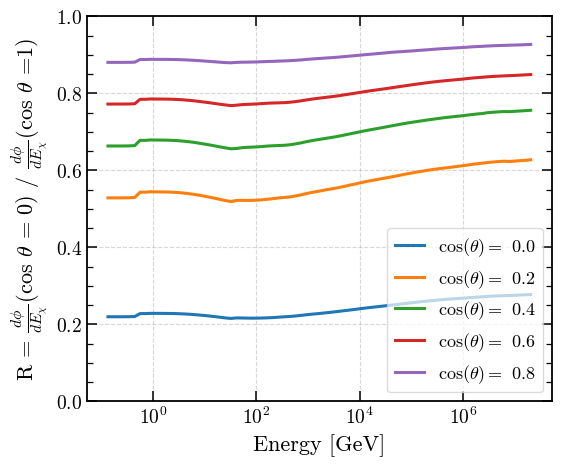

In [35]:

# ---------------------------------------------------------------------------------
# Cociente R = flujo(cos θ) / flujo(cos θ = 1) para la SUMA de todos los mesones.
# Correr desde la carpeta donde están los csv (Scripts/Data/mesones).
# ---------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
 
np.seterr(all='ignore')          # no mostrar avisos por dividir por cero (masas sin flujo)
 
mesones = ['PI0', 'ETA', 'RHO', 'OMEGA', 'PHI', 'JPSI']   # sacar 'JPSI' para no incluirlo
cosenos = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
E = np.logspace(np.log10(0.135), np.log10(2e7), 80)      # grilla común de energías [GeV]
 
# Leo los archivos
datos = {}
for meson in mesones:
    df = pd.read_csv(path+'MCP_FROM_' + meson + '_SURFACE.csv')
    df.columns = ['flujo', 'E', 'cos', 'm', 'eps2']
    datos[meson] = df
 
# Grilla común de masas: todas las masas que aparecen en algún archivo
masas = np.sort(np.unique(np.concatenate([datos[x]['m'].unique() for x in mesones])))
 
 
def flujo_total(eps2):
    """Suma de los mesones en la grilla común. Devuelve un arreglo total[masa, cos, energía]."""
    total = np.zeros((len(masas), len(cosenos), len(E)))
    for meson in mesones:
        df = datos[meson][datos[meson]['eps2'] == eps2]
        masas_meson = np.sort(df['m'].unique())
 
        # a) interpolo en energía (log del flujo vs log E) para cada masa del archivo.
        #    Fuera del rango de energías del archivo, el flujo es 0.
        flujo = np.zeros((len(masas_meson), len(cosenos), len(E)))
        for i, m in enumerate(masas_meson):
            for j, c in enumerate(cosenos):
                d = df[(df['m'] == m) & (df['cos'] == c)].sort_values('E')
                f = np.exp(np.interp(np.log(E), np.log(d['E']), np.log(d['flujo'])))
                f[(E < d['E'].min()) | (E > d['E'].max())] = 0
                flujo[i, j] = f
 
        # b) interpolo en masa (vs log m), solo en las masas que este mesón puede producir
        dentro = (masas >= masas_meson.min()) & (masas <= masas_meson.max())
        interpolador = interp1d(np.log(masas_meson), flujo, axis=0)
        total[dentro] += interpolador(np.log(masas[dentro]))
    return total
 
 
# ---------------------------------------------------------------------------------
# 1) Flujo total y cociente R
# ---------------------------------------------------------------------------------
total = flujo_total(5e-9)
R = total / total[:, [5], :]               # divido por cos θ = 1 (índice 5)
 
print('Mesones sumados:', mesones)
print('\n--- Mínimo y máximo de R ---')
for j in range(5):                          # cos θ = 0, 0.2, ..., 0.8
    Rc = R[:, j, :]                         # tabla [masa, energía] para este cos θ
    i_min = np.unravel_index(np.nanargmin(Rc), Rc.shape)   # (fila, columna) del mínimo
    i_max = np.unravel_index(np.nanargmax(Rc), Rc.shape)
    print('cos = %.1f   R min = %.3f (E = %.3g GeV, m = %.3g GeV)   R max = %.3f (E = %.3g GeV, m = %.3g GeV)'
          % (cosenos[j], Rc[i_min], E[i_min[1]], masas[i_min[0]], Rc[i_max], E[i_max[1]], masas[i_max[0]]))
 
# ---------------------------------------------------------------------------------
# 2) Chequeo de eps2: repito con otro eps2 y comparo
# ---------------------------------------------------------------------------------
total_2 = flujo_total(1e-2)
R_2 = total_2 / total_2[:, [5], :]
print('\n--- Chequeo de eps2 ---')
print('diferencia relativa máxima en R entre eps2 = 5e-9 y 1e-2: %.1e' % np.nanmax(abs(R_2 / R - 1)))
 
# ---------------------------------------------------------------------------------
# 3) Chequeo de masa: a cos y E fijos, cuánto cambia R entre masas (máximo - mínimo)
# ---------------------------------------------------------------------------------
variacion = np.nanmax(R, axis=0) - np.nanmin(R, axis=0)    # tabla [cos, energía]
print('\n--- Chequeo de masa ---')
for j in range(5):
    print('cos = %.1f   variación típica = %.4f   variación máxima = %.3f (en E = %.3g GeV)'
          % (cosenos[j], np.nanmedian(variacion[j]), np.nanmax(variacion[j]), E[np.nanargmax(variacion[j])]))
 
# ---------------------------------------------------------------------------------
# 4) Gráfico: R vs energía (mediana sobre las masas)
# ---------------------------------------------------------------------------------

for j in range(5):
    plt.plot(E, np.nanmedian(R[:, j, :], axis=0),label=r'cos($\theta) = $ %.1f' % cosenos[j])
plt.xscale('log')
plt.ylim(0, 1)
plt.xlabel('Energy [GeV]')
plt.ylabel(r'R = $\frac{d\phi}{dE_\chi}$(cos $\theta$ = 0) / $\frac{d\phi}{dE_\chi}$(cos $\theta$ =1)')
plt.legend(frameon=True,framealpha=0.7,loc = 'lower right')
plt.grid(linestyle='--',alpha=0.5)
plt.savefig('R_vs_E_total.pdf')
plt.show()

Mesones sumados: ['PI0', 'ETA', 'RHO', 'OMEGA', 'PHI']

--- Mínimo y máximo de R ---
cos = 0.0   R min = 0.210 (E = 106 GeV, m = 0.12 GeV)   R max = 0.279 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.2   R min = 0.511 (E = 83.7 GeV, m = 0.09 GeV)   R max = 0.630 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.4   R min = 0.651 (E = 83.7 GeV, m = 0.14 GeV)   R max = 0.758 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.6   R min = 0.765 (E = 66 GeV, m = 0.09 GeV)   R max = 0.850 (E = 2e+07 GeV, m = 0.45 GeV)
cos = 0.8   R min = 0.878 (E = 66 GeV, m = 0.09 GeV)   R max = 0.928 (E = 2e+07 GeV, m = 0.45 GeV)

--- Chequeo por eps2 (diferencia relativa máxima con eps2 = 5e-9) ---
eps2 = 5.0e-09   0.0e+00
eps2 = 8.0e-09   3.9e-13
eps2 = 9.5e-09   3.8e-13
eps2 = 1.0e-08   2.9e-13
eps2 = 2.0e-08   2.9e-13
eps2 = 5.0e-08   3.9e-13
eps2 = 8.0e-08   3.0e-13
eps2 = 1.0e-07   7.2e-13
eps2 = 2.0e-07   3.9e-13
eps2 = 5.0e-07   6.9e-13
eps2 = 8.0e-07   1.0e-12
eps2 = 1.0e-06   6.9e-13
eps2 = 2.0e-06   3.6e-13
eps2 = 5.0e-06   3.

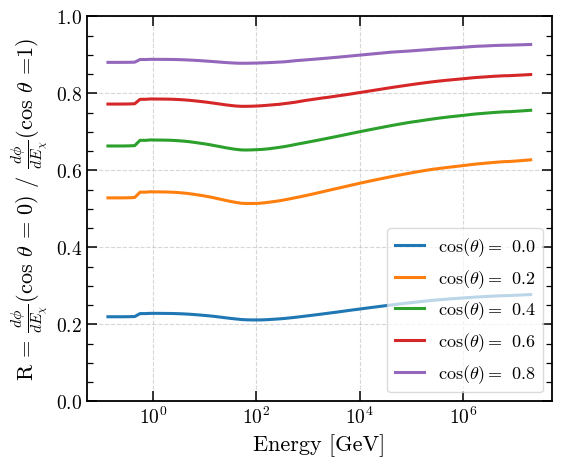

/tmp/ipykernel_43653/1469026037.py:117: UserWarning: Glyph 225 (\N{LATIN SMALL LETTER A WITH ACUTE}) missing from font(s) cmr10.
  fig.tight_layout()
/tmp/ipykernel_43653/1469026037.py:118: UserWarning: Glyph 225 (\N{LATIN SMALL LETTER A WITH ACUTE}) missing from font(s) cmr10.
  fig.savefig('chequeos_eps2_masa.pdf')
/home/lurishi/miniconda3/envs/lambda/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 225 (\N{LATIN SMALL LETTER A WITH ACUTE}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


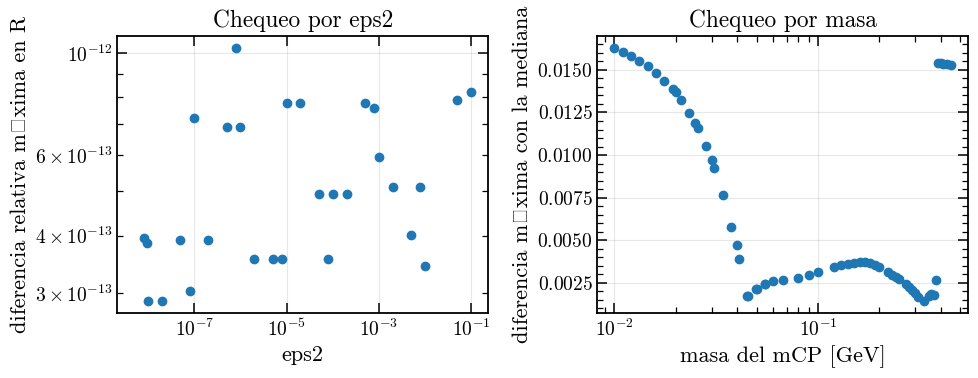

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

np.seterr(all='ignore')          # no mostrar avisos por dividir por cero (masas sin flujo)

mesones = ['PI0', 'ETA', 'RHO', 'OMEGA', 'PHI']   # sacar 'JPSI' para no incluirlo
cosenos = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
E = np.logspace(np.log10(0.135), np.log10(2e7), 80)      # grilla común de energías [GeV]

# Leo los archivos
datos = {}
for meson in mesones:
    df = pd.read_csv(path+'MCP_FROM_' + meson + '_SURFACE.csv')
    df.columns = ['flujo', 'E', 'cos', 'm', 'eps2']
    datos[meson] = df

# Grilla común de masas: todas las masas que aparecen en algún archivo
masas = np.sort(np.unique(np.concatenate([datos[x]['m'].unique() for x in mesones])))


def flujo_total(eps2):
    """Suma de los mesones en la grilla común. Devuelve un arreglo total[masa, cos, energía]."""
    total = np.zeros((len(masas), len(cosenos), len(E)))
    for meson in mesones:
        df = datos[meson][datos[meson]['eps2'] == eps2]
        masas_meson = np.sort(df['m'].unique())

        # a) interpolo en energía (log del flujo vs log E) para cada masa del archivo.
        #    Fuera del rango de energías del archivo, el flujo es 0.
        flujo = np.zeros((len(masas_meson), len(cosenos), len(E)))
        for i, m in enumerate(masas_meson):
            for j, c in enumerate(cosenos):
                d = df[(df['m'] == m) & (df['cos'] == c)].sort_values('E')
                f = np.exp(np.interp(np.log(E), np.log(d['E']), np.log(d['flujo'])))
                f[(E < d['E'].min()) | (E > d['E'].max())] = 0
                flujo[i, j] = f

        # b) interpolo en masa (vs log m), solo en las masas que este mesón puede producir
        dentro = (masas >= masas_meson.min()) & (masas <= masas_meson.max())
        interpolador = interp1d(np.log(masas_meson), flujo, axis=0)
        total[dentro] += interpolador(np.log(masas[dentro]))
    return total


# ---------------------------------------------------------------------------------
# 1) Flujo total y cociente R
# ---------------------------------------------------------------------------------
total = flujo_total(5e-9)
R = total / total[:, [5], :]               # divido por cos θ = 1 (índice 5)

print('Mesones sumados:', mesones)
print('\n--- Mínimo y máximo de R ---')
for j in range(5):                          # cos θ = 0, 0.2, ..., 0.8
    Rc = R[:, j, :]                         # tabla [masa, energía] para este cos θ
    i_min = np.unravel_index(np.nanargmin(Rc), Rc.shape)   # (fila, columna) del mínimo
    i_max = np.unravel_index(np.nanargmax(Rc), Rc.shape)
    print('cos = %.1f   R min = %.3f (E = %.3g GeV, m = %.3g GeV)   R max = %.3f (E = %.3g GeV, m = %.3g GeV)'
          % (cosenos[j], Rc[i_min], E[i_min[1]], masas[i_min[0]], Rc[i_max], E[i_max[1]], masas[i_max[0]]))

# ---------------------------------------------------------------------------------
# 2) Chequeo por eps2: repito la cuenta para TODOS los eps2 del archivo
#    y comparo R con el de eps2 = 5e-9, punto a punto.
# ---------------------------------------------------------------------------------
eps2_todos = np.sort(datos['PI0']['eps2'].unique())
dif_eps2 = []
print('\n--- Chequeo por eps2 (diferencia relativa máxima con eps2 = 5e-9) ---')
for eps2 in eps2_todos:
    t = flujo_total(eps2)
    R_e = t / t[:, [5], :]
    dif_eps2.append(np.nanmax(abs(R_e / R - 1)))
    print('eps2 = %.1e   %.1e' % (eps2, dif_eps2[-1]))

# ---------------------------------------------------------------------------------
# 3) Chequeo por masa: para cada masa comparo su R con la mediana de todas las masas
#    (a cos θ y E fijos) y me quedo con la diferencia más grande.
# ---------------------------------------------------------------------------------
R_mediana = np.nanmedian(R, axis=0)                     # tabla [cos, energía]
dif_masa = []
print('\n--- Chequeo por masa (diferencia máxima de R con la mediana de las masas) ---')
for i, m in enumerate(masas):
    dif_masa.append(np.nanmax(abs(R[i] - R_mediana)))
    print('m = %.4f GeV   %.3f' % (m, dif_masa[-1]))

# ---------------------------------------------------------------------------------
# 4) Gráficos
# ---------------------------------------------------------------------------------
# 4a) R vs energía (mediana sobre las masas)
plt.figure()
for j in range(5):
    plt.plot(E, np.nanmedian(R[:, j, :], axis=0), label=r'cos($\theta) = $ %.1f' % cosenos[j])
plt.xscale('log')
plt.ylim(0, 1)
plt.xlabel('Energy [GeV]')
plt.ylabel(r'R = $\frac{d\phi}{dE_\chi}$(cos $\theta$ = 0) / $\frac{d\phi}{dE_\chi}$(cos $\theta$ =1)')
plt.legend(frameon=True,framealpha=0.7,loc = 'lower right')
plt.grid(linestyle='--',alpha=0.5)
plt.savefig('R_vs_E_total.pdf')
plt.show()

# 4b) Chequeos: diferencia vs eps2 y vs masa
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(eps2_todos, dif_eps2, 'o')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('eps2')
ax[0].set_ylabel('diferencia relativa máxima en R')
ax[0].set_title('Chequeo por eps2')
ax[0].grid(alpha=0.3)
ax[1].plot(masas, dif_masa, 'o')
ax[1].set_xscale('log')
ax[1].set_xlabel('masa del mCP [GeV]')
ax[1].set_ylabel('diferencia máxima con la mediana')
ax[1].set_title('Chequeo por masa')
ax[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig('chequeos_eps2_masa.pdf')
plt.show()


# $\text{Divergence of the numerical method for PB}$

In [37]:
PB_flux = pd.read_csv('Data/PB_differential_flux_test_figure.csv')
p_arrival_1_PB_test = P_arrival((1e-4)**(1/2), PB_flux['Echi'],0,1500, 0) 

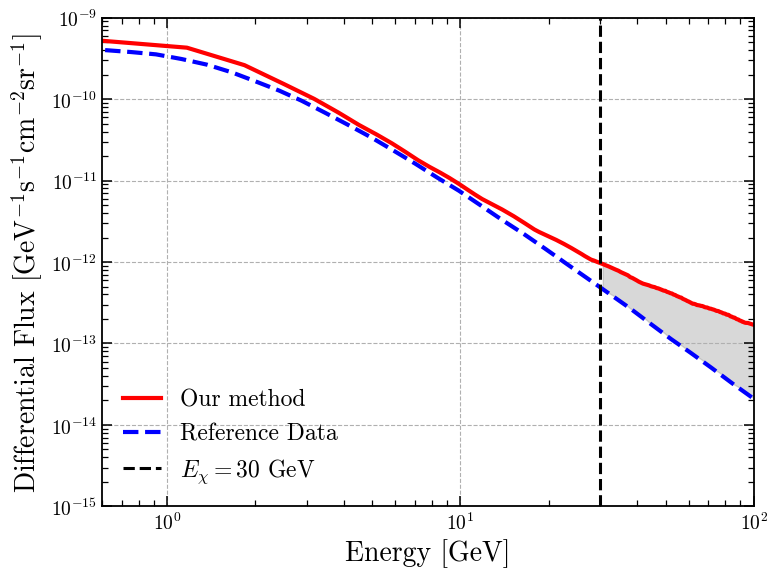

In [50]:
ig, ax = plt.subplots(figsize=(8, 6))

our_energy = PB_flux["Echi"].to_numpy()
our_flux = (PB_flux["dPhi"] * p_arrival_1_PB_test).to_numpy()

reference_energy = np.asarray(E_CONTROL_PB_1)
reference_flux = np.asarray(F_CONTROL_PB_1)

# Referencia interpolada sobre la malla de energía de nuestro método
reference_flux_interp = np.interp(
    our_energy,
    reference_energy,
    reference_flux,
    left=np.nan,
    right=np.nan,
)

mask = (
    (our_energy > 30)
    & (our_energy <= 100)
    & np.isfinite(our_flux)
    & np.isfinite(reference_flux_interp)
)

ax.plot(
    our_energy,
    our_flux,
    label="Our method",
    color="red",
    linewidth=3,
)

ax.plot(
    reference_energy,
    reference_flux,
    label="Reference Data",
    color="blue",
    linewidth=3,
    linestyle="--",
)

ax.axvline(
    30,
    color="k",
    linestyle="--",
    label=r"$E_\chi = 30$ GeV",
)

ax.fill_between(
    our_energy[mask],
    our_flux[mask],
    reference_flux_interp[mask],
    color="gray",
    alpha=0.3,
)

ax.set_xlabel("Energy [GeV]", fontsize=20)
ax.set_ylabel(
    r"Differential Flux [$\mathrm{GeV}^{-1}\mathrm{s}^{-1}"
    r"\mathrm{cm}^{-2}\mathrm{sr}^{-1}$]",
    fontsize=20,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(6e-1, 1e2)
ax.set_ylim(1e-15, 1e-9)
ax.grid(True, ls="--")
ax.legend(fontsize = 17)

plt.tight_layout()
plt.savefig(
    "/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/"
    "Reporte/Figures/PB_flux_test_figure.pdf",
    dpi=300,
)
plt.show()

# $\text{Integration check}$

In [3]:
path = 'Data'
df_pi0_=pd.read_csv(path+r'/MCP_FROM_PI0_SURFACE.csv' )
df_eta_=pd.read_csv(path+r'/MCP_FROM_ETA_SURFACE.csv' )
df_omega_=pd.read_csv(path+r'/MCP_FROM_OMEGA_SURFACE.csv' )
df_rho_=pd.read_csv(path+r'/MCP_FROM_RHO_SURFACE.csv'  )
df_phi_=pd.read_csv(path+r'/MCP_FROM_PHI_SURFACE.csv' )
df_jpsi_=pd.read_csv(path+r'/MCP_FROM_JPSI_SURFACE.csv'  )

In [4]:
df_pi0__ = df_pi0_[df_pi0_['cosTh'] == 1.0]
df_eta__ = df_eta_[df_eta_['cosTh'] == 1.0]
df_omega__ = df_omega_[df_omega_['cosTh'] == 1.0]
df_rho__ = df_rho_[df_rho_['cosTh'] == 1.0]
df_phi__ = df_phi_[df_phi_['cosTh'] == 1.0]
df_jpsi__ = df_jpsi_[df_jpsi_['cosTh'] == 1.0]

eps2 = 1e-5

df_pi0 = df_pi0__[df_pi0_['eps2'] == eps2]
df_eta = df_eta__[df_eta_['eps2'] == eps2]
df_omega = df_omega__[df_omega_['eps2'] == eps2]
df_rho = df_rho__[df_rho_['eps2'] == eps2]
df_phi = df_phi__[df_phi_['eps2'] == eps2]
df_jpsi = df_jpsi__[df_jpsi_['eps2'] == eps2]

df = [df_pi0, df_eta, df_omega, df_rho, df_phi, df_jpsi]
masses = [df_pi0['m(GeV)'].unique(), df_eta['m(GeV)'].unique(), df_omega['m(GeV)'].unique(), df_rho['m(GeV)'].unique(), df_phi['m(GeV)'].unique(), df_jpsi['m(GeV)'].unique()] # GeV

flujo_md = []
# Loopea sobre los mesones
for i in range(len(masses)):
    mass = masses[i]
    flux = np.zeros(len(mass))
    # Loopea sobre las masas
    for j in range(len(mass)):
        E = df[i]['Energy (GeV)'][df[i]['m(GeV)'] == mass[j]].values
        dif_flux = df[i]['dphi_dEdCth(1/GeV/s/cm2)'][df[i]['m(GeV)'] == mass[j]].values
        # Sort by energy to ensure correct integration sign
        order = np.argsort(E)
        E_sorted = E[order]
        dif_sorted = dif_flux[order]
        flux[j] = simpson(dif_sorted, E_sorted)/2*np.pi
    flujo_md.append(flux)

/tmp/ipykernel_65429/2668830435.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_pi0 = df_pi0__[df_pi0_['eps2'] == eps2]
/tmp/ipykernel_65429/2668830435.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_eta = df_eta__[df_eta_['eps2'] == eps2]
/tmp/ipykernel_65429/2668830435.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_omega = df_omega__[df_omega_['eps2'] == eps2]
/tmp/ipykernel_65429/2668830435.py:13: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_rho = df_rho__[df_rho_['eps2'] == eps2]
/tmp/ipykernel_65429/2668830435.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_phi = df_phi__[df_phi_['eps2'] == eps2]
/tmp/ipykernel_65429/2668830435.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_jpsi = df_jpsi__[df_jpsi_['eps2'] == eps2]


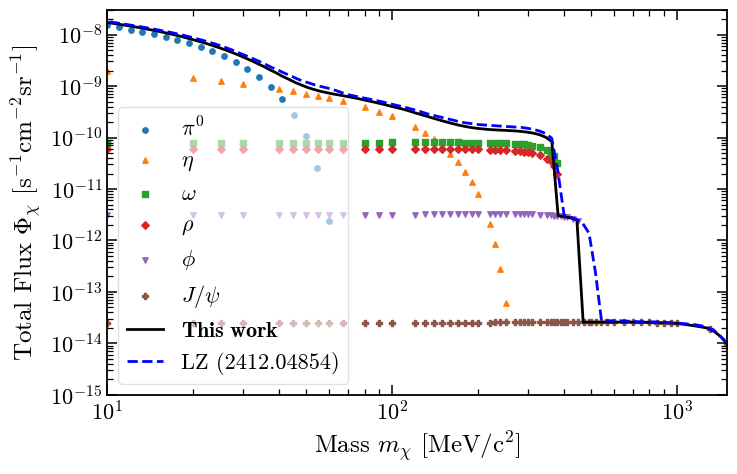

In [6]:
common_mass_ = np.unique(np.concatenate([np.asarray(m) for m in masses]))
common_mass = np.logspace(np.log10(common_mass_[0]), np.log10(common_mass_[-1]), 100)

df_lz = pd.read_csv('Data/Flujo_MD_interpolado.csv')
mass_col = 'Masa[MeV/c2]'
flux_col = 'Flujo[s-1cm-2]'

lz_sorted = df_lz.sort_values(mass_col)

lz_mass = lz_sorted[mass_col].to_numpy()
lz_flux = lz_sorted[flux_col].to_numpy()

# Símbolos y nombres de los mesones.
markers = ['o', '^', 's','D', 'v', 'P']
meson_names = [r'$\pi^0$', r'$\eta$', r'$\omega$', r'$\rho$', r'$\phi$', r'$J/\psi$']

flujo_md_interp = []
fig = plt.figure(figsize=(8, 5))
for i in range(len(masses)):
    plt.scatter(
        masses[i]*1000,
        flujo_md[i],
        marker=markers[i],
        label=meson_names[i],
        s=15
    )

    mass_sorted_idx = np.argsort(masses[i])
    mass_sorted = np.asarray(masses[i])[mass_sorted_idx]
    flux_sorted = np.asarray(flujo_md[i])[mass_sorted_idx]

    unique_mask = np.concatenate(([True], np.diff(mass_sorted) != 0))
    mass_unique = mass_sorted[unique_mask]
    flux_unique = flux_sorted[unique_mask]

    flujo_md_interp.append(
        np.interp(
            common_mass,
            mass_unique,
            flux_unique,
            left=0.0,
            right=0.0
        )
    )

# Sumar las contribuciones interpoladas.
flujo_total = np.sum(flujo_md_interp, axis=0)

plt.plot(
    common_mass*1000,
    flujo_total,
    label=r'$\mathbf{This\; work}$',
    color='black',
    linewidth=2,
    linestyle='-'
)

plt.plot(
    lz_mass,
    lz_flux / (2 * np.pi),
    label='LZ (2412.04854)',
    color='blue',linestyle='--',linewidth=2
)

plt.xlabel(r'Mass $m_\chi$ [MeV/$\text{c}^2$]', fontsize=18)
plt.ylabel(r"Total Flux $\Phi_\chi$ [s$^{-1}$cm$^{-2}$sr$^{-1}$]", fontsize=18)

plt.xscale('log')
plt.yscale('log')
#plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlim(1e1,np.max(common_mass)*1000)
plt.ylim(1e-15,3e-8)
plt.legend(fontsize=16, loc='lower left',frameon=True,framealpha=0.6)
plt.savefig('/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Reporte/Figures/Comparison.pdf',dpi=300, bbox_inches='tight')
plt.show()
